# Cresci-2017: text signals

Streams both tweet files once, then reports integrity, class balance, text patterns, leakage-prone columns and built-in test-set flags.

**Key takeaways**
- 3,474 genuine users / 991 spambot users; 2,839,362 / 1,610,034 tweets (balance 77.81% / 22.19% users).
- Median tweet length: 64 chars genuine vs 87 spambot; mean words 11.14 vs 14.76.
- Duplicate text within class: 4.37% genuine vs 90.30% spambot; cross-class overlap is tiny (0.04% / 0.02%).
- `source` (tweets), `test_set_1`, `test_set_2`, `crawled_at` and `updated` separate the classes and must be excluded from training.


## Setup: imports, helpers, output folders

In [1]:
from __future__ import annotations

import collections
import io
import json
import re
import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.util import hash_pandas_object
from IPython.display import Image as IPythonImage, display

def find_repo_root(start: Path) -> Path:
    for p in (start, *start.parents):
        if (p / "requirements.txt").is_file() and (p / ".git").exists():
            return p
    raise RuntimeError("Could not locate the repository root")


DATA_DIR = find_repo_root(Path.cwd()) / "data" / "raw" / "cresci_2017"

CHUNKSIZE = 100_000
CLASSES = [
    {"name": "genuine", "folder": "genuine_accounts", "label": 0},
    {"name": "spambot", "folder": "social_spambots", "label": 1},
]
TWEET_COLS = [
    "id", "text", "source", "user_id", "truncated", "in_reply_to_status_id",
    "in_reply_to_user_id", "in_reply_to_screen_name", "retweeted_status_id",
    "geo", "place", "contributors", "retweet_count", "reply_count",
    "favorite_count", "favorited", "retweeted", "possibly_sensitive",
    "num_hashtags", "num_urls", "num_mentions", "created_at", "timestamp",
    "crawled_at", "updated",
]
TIME_COLS = ["created_at", "timestamp", "crawled_at", "updated"]
FMT_CREATED = "%a %b %d %H:%M:%S %z %Y"
FMT_NAIVE = "%Y-%m-%d %H:%M:%S"
TODAY = pd.Timestamp("2026-11-22")


def read_csv(*args, **kwargs):
    # both tweet files contain isolated non-UTF-8 bytes; keep UTF-8 where valid
    # and replace undecodable bytes so every row is read consistently.
    kwargs.setdefault("encoding", "utf-8")
    kwargs.setdefault("encoding_errors", "replace")
    return pd.read_csv(*args, **kwargs)

URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
WORD_RE = re.compile(r"[^\W_]+", re.UNICODE)
HASHTAG_RE = re.compile(r"#([^\W_]+)", re.UNICODE)
MENTION_RE = re.compile(r"@([^\W_]+)", re.UNICODE)
SCRIPT_RES = {
    "Latin": re.compile(r"[A-Za-zÀ-ÖØ-öø-ÿ]"),
    "Cyrillic": re.compile(r"[\u0400-\u04FF]"),
    "Greek": re.compile(r"[\u0370-\u03FF]"),
    "Arabic": re.compile(r"[\u0600-\u06FF]"),
    "Hebrew": re.compile(r"[\u0590-\u05FF]"),
    "Japanese_kana": re.compile(r"[\u3040-\u30FF]"),
    "CJK_ideographs": re.compile(r"[\u4E00-\u9FFF]"),
    "Hangul": re.compile(r"[\uAC00-\uD7AF]"),
    "Devanagari": re.compile(r"[\u0900-\u097F]"),
    "Thai": re.compile(r"[\u0E00-\u0E7F]"),
}

_print_counter = {"n": 0}


def section(title: str) -> None:
    print("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90, flush=True)


def show(name: str, df: pd.DataFrame, print_rows: int = 12) -> None:
    print(f"\n--- {name} --- ({len(df)} rows)", flush=True)
    with pd.option_context("display.max_rows", print_rows + 5, "display.width", 220,
                           "display.max_columns", 60):
        display(df.head(print_rows))


def plot(name: str) -> None:
    plt.tight_layout()
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=110)
    plt.close()
    buf.seek(0)
    display(IPythonImage(data=buf.getvalue()))


def q(s: pd.Series | np.ndarray) -> dict:
    a = pd.Series(np.asarray(s, dtype="float64")).dropna()
    if a.empty:
        return {k: np.nan for k in ("count", "min", "p25", "median", "p75", "p95", "max", "mean")}
    return {
        "count": int(a.size), "min": a.min(), "p25": a.quantile(0.25),
        "median": a.quantile(0.5), "p75": a.quantile(0.75),
        "p95": a.quantile(0.95), "max": a.max(), "mean": a.mean(),
    }


def parse_times(s: pd.Series, fmt: str) -> tuple[np.ndarray, int, int, int]:
    """Return epoch seconds (NaN for missing/failed), n_null, n_parse_fail, n_recovered."""
    raw_null = int(s.isna().sum())
    parsed = pd.to_datetime(s, format=fmt, errors="coerce", utc=True)
    fail_mask = parsed.isna() & s.notna()
    n_fail = int(fail_mask.sum())
    n_recovered = 0
    if n_fail:
        retry = pd.to_datetime(s[fail_mask], errors="coerce", utc=True)
        n_recovered = int(retry.notna().sum())
        parsed.loc[fail_mask] = retry
    unit = str(getattr(parsed.dtype, "unit", "us"))
    divisor = {"s": 1.0, "ms": 1e3, "us": 1e6, "ns": 1e9}[unit]
    sec = parsed.astype("int64").astype("float64") / divisor
    sec[parsed.isna().to_numpy()] = np.nan
    return sec, raw_null, n_fail, n_recovered


def most_common(counter: collections.Counter, n: int = 30) -> pd.DataFrame:
    return pd.DataFrame(counter.most_common(n), columns=["term", "count"])


def script_of(text: str) -> str:
    counts = {name: len(rx.findall(text)) for name, rx in SCRIPT_RES.items()}
    best = max(counts, key=counts.get)
    return best if counts[best] > 0 else "none/numeric-only"


def cat_audit_counts(name: str, source: str, a: pd.Series, b: pd.Series,
                     label0: str = "genuine", label1: str = "spambot", min_freq: int = 10) -> dict:
    """Quantify one-class-only values and class purity from two value-count Series."""
    idx = a.index.union(b.index)
    t = pd.DataFrame({label0: a.reindex(idx, fill_value=0), label1: b.reindex(idx, fill_value=0)})
    only0 = (t[label1] == 0) & (t[label0] > 0)
    only1 = (t[label0] == 0) & (t[label1] > 0)
    share_only0 = float(t.loc[only0, label0].sum() / max(int(a.sum()), 1))
    share_only1 = float(t.loc[only1, label1].sum() / max(int(b.sum()), 1))
    big = t[(t[label0] + t[label1]) >= min_freq]
    purity = (big[[label0, label1]].max(axis=1) / big[[label0, label1]].sum(axis=1)) if len(big) else pd.Series(dtype=float)
    max_purity = float(purity.max()) if len(purity) else np.nan
    top_val = purity.idxmax() if len(purity) else "<none>"
    top_n = int((t.loc[top_val, label0] + t.loc[top_val, label1])) if len(purity) else 0
    top_split = f"{label0}={int(t.loc[top_val, label0])}/{label1}={int(t.loc[top_val, label1])}" if len(purity) else ""
    worst_share = max(share_only0, share_only1)
    verdict = ("HIGH" if worst_share >= 0.90 or (max_purity >= 0.99 and top_n >= 0.5 * max(int(a.sum()), int(b.sum())))
               else "MEDIUM" if worst_share >= 0.50 or max_purity >= 0.95
               else "LOW")
    evidence = (
        f"distinct={len(idx)}; {label0}-only values={int(only0.sum())} covering {share_only0:.1%} of {label0} rows; "
        f"{label1}-only values={int(only1.sum())} covering {share_only1:.1%} of {label1} rows; "
        f"max class purity among values with n>={min_freq}: {max_purity:.4f} at '{top_val}' (n={top_n}, {top_split})"
    )
    return {"column": name, "source_file": source, "evidence": evidence,
            "separation_verdict": verdict}


def cat_audit(name: str, source: str, s0: pd.Series, s1: pd.Series, **kwargs) -> dict:
    a = s0.astype("string").fillna("<MISSING>").value_counts()
    b = s1.astype("string").fillna("<MISSING>").value_counts()
    return cat_audit_counts(name, source, a, b, **kwargs)


# ---------------------------------------------------------------------------
# Load users (small files) and metadata needed for the tweet streaming pass


## Load users; record headers and dtypes

In [2]:
# ---------------------------------------------------------------------------
section("LOADING USERS + RECORDING HEADERS/DTYPES")

users, user_meta = {}, {}
header_rows, dtype_rows, missing_user_rows = [], [], []

for c in CLASSES:
    name, folder = c["name"], c["folder"]
    upath = DATA_DIR / folder / "users.csv"
    tpath = DATA_DIR / folder / "tweets.csv"
    u = read_csv(upath, dtype=str)
    u_inferred = read_csv(upath, nrows=50_000)
    t_inferred = read_csv(tpath, nrows=50_000)
    users[name] = u
    user_meta[name] = {
        "label": c["label"], "path": upath, "tpath": tpath,
        "uids": pd.to_numeric(u["id"], errors="coerce").dropna().astype("int64").to_numpy(),
        "columns": list(u.columns),
    }
    for i, col in enumerate(u.columns):
        header_rows.append({"file": "users.csv", "class": name, "position": i, "column": col})
    for i, col in enumerate(t_inferred.columns):
        header_rows.append({"file": "tweets.csv", "class": name, "position": i, "column": col})
    for f, d in (("users.csv", u_inferred), ("tweets.csv", t_inferred)):
        for col in d.columns:
            dtype_rows.append({"file": f, "class": name, "column": col,
                               "inferred_dtype_first_50k": str(d[col].dtype)})
    for col in u.columns:
        miss = int(u[col].isna().sum())
        missing_user_rows.append({"class": name, "file": "users.csv", "column": col,
                                  "missing": miss, "missing_pct": 100 * miss / len(u)})
    print(f"{name}: users={len(u)} x {u.shape[1]}, tweets columns={t_inferred.shape[1]}", flush=True)

show("01_headers", pd.DataFrame(header_rows), print_rows=12)
show("01_dtypes", pd.DataFrame(dtype_rows), print_rows=12)

gu, su = set(users["genuine"].columns), set(users["spambot"].columns)
col_diff = pd.DataFrame([
    {"column": c, "in_genuine_users": c in gu, "in_spambot_users": c in su}
    for c in sorted(gu | su)
])
show("01_users_column_set_diff", col_diff, print_rows=12)
print("observed: users.csv column sets identical?", gu == su,
      "| only genuine:", sorted(gu - su), "| only spambot:", sorted(su - gu), flush=True)

# ---------------------------------------------------------------------------
# Stream tweets



LOADING USERS + RECORDING HEADERS/DTYPES


genuine: users=3474 x 42, tweets columns=25


spambot: users=991 x 41, tweets columns=25



--- 01_headers --- (133 rows)


/tmp/ipykernel_191966/4230236118.py:52: DtypeWarning: Columns (9: geo, 10: place) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(*args, **kwargs)


,file,class,position,column
0,users.csv,genuine,0,id
1,users.csv,genuine,1,name
2,users.csv,genuine,2,screen_name
3,users.csv,genuine,3,statuses_count
4,users.csv,genuine,4,followers_count
5,users.csv,genuine,5,friends_count
6,users.csv,genuine,6,favourites_count
7,users.csv,genuine,7,listed_count
8,users.csv,genuine,8,url
9,users.csv,genuine,9,lang



--- 01_dtypes --- (133 rows)


,file,class,column,inferred_dtype_first_50k
0,users.csv,genuine,id,int64
1,users.csv,genuine,name,str
2,users.csv,genuine,screen_name,str
3,users.csv,genuine,statuses_count,int64
4,users.csv,genuine,followers_count,int64
5,users.csv,genuine,friends_count,int64
6,users.csv,genuine,favourites_count,int64
7,users.csv,genuine,listed_count,int64
8,users.csv,genuine,url,str
9,users.csv,genuine,lang,str



--- 01_users_column_set_diff --- (42 rows)


,column,in_genuine_users,in_spambot_users
0,contributors_enabled,True,True
1,crawled_at,True,True
2,created_at,True,True
3,default_profile,True,True
4,default_profile_image,True,True
5,description,True,True
6,favourites_count,True,True
7,follow_request_sent,True,True
8,followers_count,True,True
9,following,True,True


observed: users.csv column sets identical? False | only genuine: ['test_set_2'] | only spambot: []


## Stream tweets in chunks (integrity, timing, text counters)

In [3]:
# ---------------------------------------------------------------------------
section("STREAMING TWEETS IN CHUNKS (all columns as strings for stable row hashes)")

tweet_state = {}
for c in CLASSES:
    name = c["name"]
    st = {
        "n": 0, "chunk_i": 0,
        "missing": collections.Counter(),
        "row_hashes": [], "id_hashes": [], "text_hashes": [], "text_valid": [],
        "uid": [], "ts": [], "ca": [],
        "char_len": [], "word_len": [],
        "user_counts": collections.Counter(),
        "uid_missing": 0, "uid_null": 0,
        "time_null": collections.Counter(), "time_fail": collections.Counter(),
        "time_recovered": collections.Counter(),
        "time_min": {k: np.inf for k in TIME_COLS}, "time_max": {k: -np.inf for k in TIME_COLS},
        "time_epoch0": collections.Counter(),
        "time_future_today": collections.Counter(),
        "time_future_max_updated": collections.Counter(),
        "created_offsets": collections.Counter(),
        "ts_minus_ca": collections.Counter(),
        "offset_month": collections.Counter(),
        "retweet_raw_nonnull": 0, "retweet_nonzero": 0,
        "src_counter": collections.Counter(), "crawl_counter": collections.Counter(),
        "updated_counter": collections.Counter(),
        "words": collections.Counter(), "hashtags": collections.Counter(),
        "mentions": collections.Counter(), "scripts": collections.Counter(),
        "num_hashtags_sum": 0, "num_mentions_sum": 0, "num_urls_sum": 0,
        "sample_texts": [],
    }
    tweet_state[name] = st
    uids = user_meta[name]["uids"]
    tpath = user_meta[name]["tpath"]
    raw_head = read_csv(tpath, nrows=10, dtype=str)
    st["raw_head"] = raw_head[TIME_COLS].copy()

    print(f"\n[{name}] streaming {tpath.name} ...", flush=True)
    reader = read_csv(tpath, dtype=str, chunksize=CHUNKSIZE)
    for chunk in reader:
        st["chunk_i"] += 1
        n = len(chunk)
        st["n"] += n
        st["missing"].update(chunk.isna().sum().to_dict())

        # Exact duplicate rows and duplicate tweet ids via collision-resistant hashes
        st["row_hashes"].append(hash_pandas_object(chunk, index=False).to_numpy())
        st["id_hashes"].append(hash_pandas_object(chunk["id"], index=False).to_numpy())

        uid = pd.to_numeric(chunk["user_id"], errors="coerce")
        uid_arr = uid.fillna(-1).to_numpy(dtype="int64")
        st["uid_null"] += int(uid.isna().sum())
        present = np.isin(uid_arr, uids)
        st["uid_missing"] += int((~present).sum())
        vc = collections.Counter(uid_arr[present].tolist())
        st["user_counts"].update(vc)

        # Time columns (seconds since epoch; naive local strings parsed as UTC)
        ca, null_ca, fail_ca, rec_ca = parse_times(chunk["created_at"], FMT_CREATED)
        ts, null_ts, fail_ts, rec_ts = parse_times(chunk["timestamp"], FMT_NAIVE)
        cr, null_cr, fail_cr, rec_cr = parse_times(chunk["crawled_at"], FMT_NAIVE)
        up, null_up, fail_up, rec_up = parse_times(chunk["updated"], FMT_NAIVE)
        arrs = {"created_at": ca, "timestamp": ts, "crawled_at": cr, "updated": up}
        nulls = {"created_at": null_ca, "timestamp": null_ts, "crawled_at": null_cr, "updated": null_up}
        fails = {"created_at": fail_ca, "timestamp": fail_ts, "crawled_at": fail_cr, "updated": fail_up}
        recs = {"created_at": rec_ca, "timestamp": rec_ts, "crawled_at": rec_cr, "updated": rec_up}
        for k, arr in arrs.items():
            st["time_null"][k] += nulls[k]
            st["time_fail"][k] += fails[k]
            st["time_recovered"][k] += recs[k]
            v = arr[np.isfinite(arr)]
            if v.size:
                st["time_min"][k] = min(st["time_min"][k], v.min())
                st["time_max"][k] = max(st["time_max"][k], v.max())
            st["time_epoch0"][k] += int(np.sum(arr == 0))
            st["time_future_today"][k] += int(np.sum(arr > TODAY.timestamp()))
        # compared with dataset max updated after the pass; stored arrays needed for that
        st["ca"].append(ca)
        st["ts"].append(ts)
        st["uid"].append(uid_arr)

        off = chunk["created_at"].str.extract(r"([+-]\d{4}) \d{4}$", expand=False)
        st["created_offsets"].update(off.fillna("<unparsed>").value_counts().to_dict())
        diff = np.round(ts - ca)
        st["ts_minus_ca"].update(
            collections.Counter(int(x) for x in diff[np.isfinite(diff)]))
        months = pd.to_datetime(ca[np.isfinite(ca)], unit="s", utc=True).dt.month.to_numpy()
        st["offset_month"].update(
            collections.Counter(zip(diff[np.isfinite(diff)].astype("int64").tolist(), months.tolist())))

        # Text metrics
        txt = chunk["text"]
        st["char_len"].append(pd.to_numeric(txt.str.len(), errors="coerce").fillna(-1).to_numpy(dtype="int32"))
        words_per = txt.str.split().str.len()
        st["word_len"].append(pd.to_numeric(words_per, errors="coerce").fillna(-1).to_numpy(dtype="int32"))
        st["text_hashes"].append(hash_pandas_object(txt.fillna(""), index=False).to_numpy())
        st["text_valid"].append(txt.notna().to_numpy())
        rt = chunk["retweeted_status_id"]
        st["retweet_raw_nonnull"] += int(rt.notna().sum())
        st["retweet_nonzero"] += int(((rt.notna()) & (rt != "0")).sum())
        st["src_counter"].update(chunk["source"].dropna().value_counts().to_dict())
        st["crawl_counter"].update(chunk["crawled_at"].dropna().value_counts().to_dict())
        st["updated_counter"].update(chunk["updated"].dropna().value_counts().to_dict())
        for k in ("num_hashtags", "num_mentions", "num_urls"):
            st[f"{k}_sum"] += int(pd.to_numeric(chunk[k], errors="coerce").fillna(0).sum())

        for s in txt.dropna().tolist():
            clean = URL_RE.sub(" ", s).lower()
            toks = [w for w in WORD_RE.findall(clean) if len(w) >= 2 and not w.isdigit()]
            st["words"].update(toks)
            st["hashtags"].update(w.lower() for w in HASHTAG_RE.findall(s))
            st["mentions"].update(w.lower() for w in MENTION_RE.findall(s))

        # Deterministic 5% sample for script/language estimation
        sample = chunk.sample(frac=0.05, random_state=42) if n > 20 else chunk
        for s in sample["text"].dropna().tolist():
            st["scripts"][script_of(s)] += 1

        if st["chunk_i"] % 5 == 0 or st["chunk_i"] == 1:
            print(f"  [{name}] chunk {st['chunk_i']}: {st['n']:,} rows", flush=True)

    st["uid"] = np.concatenate(st["uid"])
    st["ts"] = np.concatenate(st["ts"])
    st["ca"] = np.concatenate(st["ca"])
    st["char_len"] = np.concatenate(st["char_len"])
    st["word_len"] = np.concatenate(st["word_len"])
    st["row_hashes"] = np.concatenate(st["row_hashes"])
    st["id_hashes"] = np.concatenate(st["id_hashes"])
    st["text_hashes"] = np.concatenate(st["text_hashes"])
    st["text_valid"] = np.concatenate(st["text_valid"])
    max_up = st["time_max"]["updated"]
    for k in TIME_COLS:
        arr = st["ca"] if k == "created_at" else st["ts"] if k == "timestamp" else None
        if arr is None:
            continue
        st["time_future_max_updated"][k] = int(np.sum(arr > max_up))
    print(f"  [{name}] DONE: {st['n']:,} tweets", flush=True)

# ---------------------------------------------------------------------------
# 1. Structure and integrity



STREAMING TWEETS IN CHUNKS (all columns as strings for stable row hashes)



[genuine] streaming tweets.csv ...


  [genuine] chunk 1: 100,000 rows


  [genuine] chunk 5: 500,000 rows


  [genuine] chunk 10: 1,000,000 rows


  [genuine] chunk 15: 1,500,000 rows


... (5 outputs left out)

  [spambot] chunk 5: 500,000 rows


  [spambot] chunk 10: 1,000,000 rows


  [spambot] chunk 15: 1,500,000 rows


  [spambot] DONE: 1,610,034 tweets


## 1. Structure and integrity

In [4]:
# ---------------------------------------------------------------------------
section("1. STRUCTURE AND INTEGRITY")

shape_rows = []
for c in CLASSES:
    name = c["name"]
    for f in ("tweets.csv", "users.csv"):
        shape_rows.append({"class": name, "label": c["label"], "file": f,
                           "rows": tweet_state[name]["n"] if f == "tweets.csv" else len(users[name]),
                           "columns": len(TWEET_COLS) if f == "tweets.csv" else users[name].shape[1],
                           "size_MB": round((user_meta[name]["tpath"] if f == "tweets.csv" else user_meta[name]["path"]).stat().st_size / 1024**2, 1)})
show("01_file_shapes", pd.DataFrame(shape_rows))

miss_rows = []
for c in CLASSES:
    name = c["name"]
    st = tweet_state[name]
    u = users[name]
    for col in TWEET_COLS:
        m = int(st["missing"][col])
        miss_rows.append({"class": name, "file": "tweets.csv", "column": col, "missing": m,
                          "missing_pct": 100 * m / st["n"]})
    for col in u.columns:
        m = int(u[col].isna().sum())
        miss_rows.append({"class": name, "file": "users.csv", "column": col, "missing": m,
                          "missing_pct": 100 * m / len(u)})
miss_df = pd.DataFrame(miss_rows)
show("01_missing_all", miss_df, print_rows=12)
print("\nLargest missing shares (tweets):", flush=True)
print(miss_df[miss_df["file"] == "tweets.csv"].nlargest(8, "missing_pct").to_string(index=False), flush=True)
print("\nLargest missing shares (users):", flush=True)
print(miss_df[miss_df["file"] == "users.csv"].nlargest(8, "missing_pct").to_string(index=False), flush=True)

dup_rows = []
for c in CLASSES:
    name = c["name"]
    st = tweet_state[name]
    dup_rows.append({"class": name, "file": "tweets.csv", "rows": st["n"],
                     "exact_duplicate_rows": int(pd.Series(st["row_hashes"]).duplicated().sum()),
                     "duplicate_id": int(pd.Series(st["id_hashes"]).duplicated().sum())})
    u = users[name]
    dup_rows.append({"class": name, "file": "users.csv", "rows": len(u),
                     "exact_duplicate_rows": int(pd.Series(hash_pandas_object(u, index=False)).duplicated().sum()),
                     "duplicate_id": int(u["id"].duplicated().sum())})
show("01_duplicates", pd.DataFrame(dup_rows))

# ---------------------------------------------------------------------------
# 2. Join and class balance



1. STRUCTURE AND INTEGRITY



--- 01_file_shapes --- (4 rows)


,class,label,file,rows,columns,size_MB
0,genuine,0,tweets.csv,2839362,25,964.6
1,genuine,0,users.csv,3474,42,2.3
2,spambot,1,tweets.csv,1610034,25,534.6
3,spambot,1,users.csv,991,41,0.6



--- 01_missing_all --- (133 rows)


,class,file,column,missing,missing_pct
0,genuine,tweets.csv,id,0,0.000000
1,genuine,tweets.csv,text,12572,0.442776
2,genuine,tweets.csv,source,73,0.002571
3,genuine,tweets.csv,user_id,1,0.000035
4,genuine,tweets.csv,truncated,2839362,100.000000
5,genuine,tweets.csv,in_reply_to_status_id,1,0.000035
6,genuine,tweets.csv,in_reply_to_user_id,1,0.000035
7,genuine,tweets.csv,in_reply_to_screen_name,2010493,70.807914
8,genuine,tweets.csv,retweeted_status_id,1,0.000035
9,genuine,tweets.csv,geo,2737293,96.405214



Largest missing shares (tweets):


  class       file       column  missing  missing_pct
genuine tweets.csv    truncated  2839362        100.0
genuine tweets.csv contributors  2839362        100.0
genuine tweets.csv    favorited  2839362        100.0
genuine tweets.csv    retweeted  2839362        100.0
spambot tweets.csv    truncated  1610034        100.0
spambot tweets.csv contributors  1610034        100.0
spambot tweets.csv    favorited  1610034        100.0
spambot tweets.csv    retweeted  1610034        100.0



Largest missing shares (users):


  class      file               column  missing  missing_pct
genuine users.csv  follow_request_sent     3474        100.0
genuine users.csv        notifications     3474        100.0
genuine users.csv contributors_enabled     3474        100.0
genuine users.csv            following     3474        100.0
spambot users.csv        is_translator      991        100.0
spambot users.csv  follow_request_sent      991        100.0
spambot users.csv            protected      991        100.0
spambot users.csv             verified      991        100.0



--- 01_duplicates --- (4 rows)


,class,file,rows,exact_duplicate_rows,duplicate_id
0,genuine,tweets.csv,2839362,0,0
1,genuine,users.csv,3474,0,0
2,spambot,tweets.csv,1610034,0,0
3,spambot,users.csv,991,0,0


## 2. Join and class balance

In [5]:
# ---------------------------------------------------------------------------
section("2. JOIN AND CLASS BALANCE")

bal_rows, join_rows = [], []
for c in CLASSES:
    name = c["name"]
    st = tweet_state[name]
    nU, nT = len(users[name]), st["n"]
    join_rows.append({"class": name, "label": c["label"], "users": nU, "tweets": nT,
                      "tweets_with_user_id_missing_from_class_users_csv": st["uid_missing"],
                      "tweets_with_null_user_id": st["uid_null"],
                      "users_with_zero_tweets": nU - len(st["user_counts"]),
                      "users_with_>=1_tweet": len(st["user_counts"])})
    bal_rows.append({"level": "user", "class": name, "label": c["label"], "count": nU})
    bal_rows.append({"level": "tweet", "class": name, "label": c["label"], "count": nT})
join_df = pd.DataFrame(join_rows)
show("02_join_audit", join_df)
bal = pd.DataFrame(bal_rows).pivot(index="level", columns="class", values="count").reset_index()
bal["total"] = bal["genuine"] + bal["spambot"]
bal["genuine_pct"] = 100 * bal["genuine"] / bal["total"]
bal["spambot_pct"] = 100 * bal["spambot"] / bal["total"]
bal["imbalance_ratio_genuine_per_spambot"] = bal["genuine"] / bal["spambot"]
show("02_class_balance", bal)

# ---------------------------------------------------------------------------
# 3. Time columns



2. JOIN AND CLASS BALANCE



--- 02_join_audit --- (2 rows)


,class,label,users,tweets,tweets_with_user_id_missing_from_class_users_csv,tweets_with_null_user_id,users_with_zero_tweets,users_with_>=1_tweet
0,genuine,0,3474,2839362,1,1,2391,1083
1,spambot,1,991,1610034,0,0,0,991



--- 02_class_balance --- (2 rows)


class,level,genuine,spambot,total,genuine_pct,spambot_pct,imbalance_ratio_genuine_per_spambot
0,tweet,2839362,1610034,4449396,63.814549,36.185451,1.763542
1,user,3474,991,4465,77.805151,22.194849,3.505550


## 6. Text


6. TEXT



--- 06_top_words_genuine --- (30 rows)


,term,count
0,rt,787046
1,the,719924
2,to,574265
3,you,461409
4,and,347175
5,is,318736
6,in,318672
7,of,304778
8,it,303740
9,for,260864



--- 06_top_hashtags_genuine --- (20 rows)


,term,count
0,kca,6896
1,vote5sos,3654
2,vote1duk,3548
3,theyretheone,2153
4,nowplaying,2073
5,новости,2031
6,news,1647
7,onedirection,1579
8,1,1487
9,ff,1468



--- 06_top_words_spambot --- (30 rows)


... (11 outputs left out)


--- 06_hashtag_mention_url --- (2 rows)


,class,tweets,mean_num_hashtags_col,mean_num_mentions_col,mean_num_urls_col,distinct_hashtags,distinct_mentions
0,genuine,2839362,0.247693,0.771442,0.150747,162878,324968
1,spambot,1610034,0.095358,0.042104,0.060898,9482,10133



--- 06_duplicate_text_cross_class --- (2 rows)


,class,tweets_with_text,tweets_whose_exact_text_also_occurs_in_other_class,pct
0,genuine,2826790,1206,0.042663
1,spambot,1609944,285,0.017702


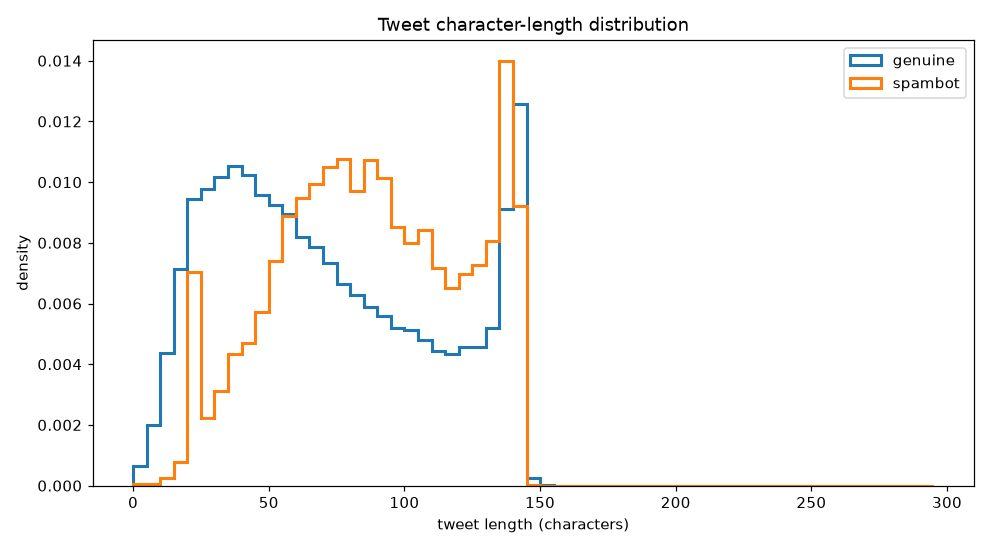

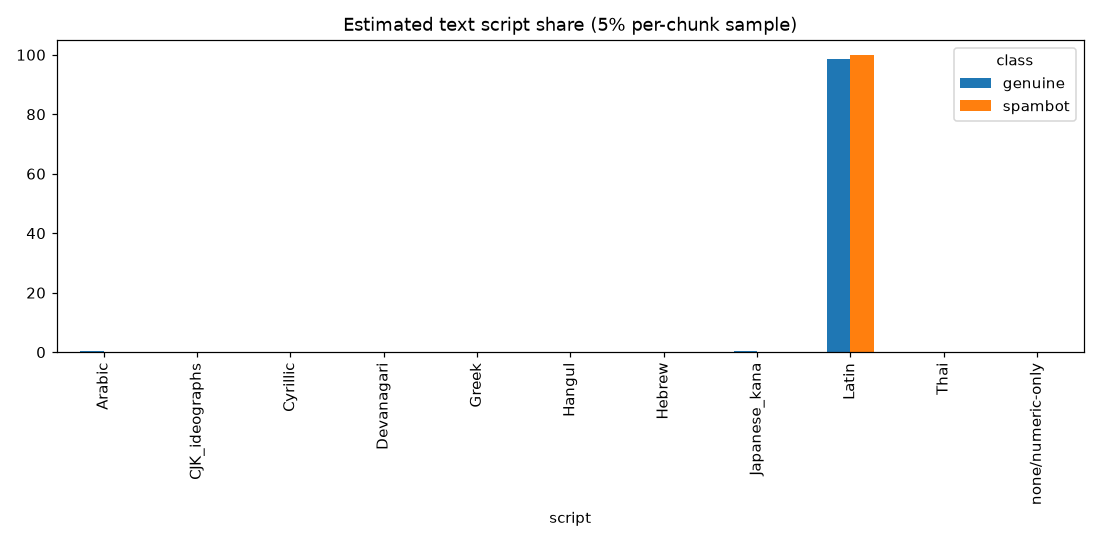

In [6]:
# ---------------------------------------------------------------------------
section("6. TEXT")

length_rows, rt_rows, dup_text_rows, script_rows, tag_rows = [], [], [], [], []
text_hash_by_class = {}
for c in CLASSES:
    name = c["name"]
    st = tweet_state[name]
    cl, wl = st["char_len"][st["char_len"] >= 0], st["word_len"][st["word_len"] >= 0]
    length_rows.append({"class": name, "label": c["label"], "tweets": len(cl),
                        **{k: q(cl)[k] for k in ("min", "p25", "median", "p75", "p95", "max", "mean")},
                        "mean_words": q(wl)["mean"], "median_words": q(wl)["median"]})
    rt_rows.append({"class": name, "label": c["label"], "tweets": st["n"],
                    "retweeted_status_id_nonnull_raw": st["retweet_raw_nonnull"],
                    "pct_nonnull_raw": 100 * st["retweet_raw_nonnull"] / st["n"],
                    "retweeted_status_id_nonnull_and_not_0": st["retweet_nonzero"],
                    "pct_nonnull_and_not_0": 100 * st["retweet_nonzero"] / st["n"],
                    "note": "'0' is used as a sentinel for non-retweets in this export"})
    h = pd.Series(st["text_hashes"][st["text_valid"]])
    dup_mask = h.duplicated(keep=False)
    vcount = h.value_counts()
    text_hash_by_class[name] = set(vcount.index.tolist())
    dup_text_rows.append({"class": name, "label": c["label"], "tweets_with_text": len(h),
                          "tweets_with_text_appearing_more_than_once_in_class": int(dup_mask.sum()),
                          "pct_within_class_duplicate_text": 100 * dup_mask.mean(),
                          "distinct_texts": int(vcount.size),
                          "max_copies_of_one_text": int(vcount.max())})
    tot = st["scripts"].total()
    script_rows.extend({"class": name, "script": k, "tweets": v, "pct": 100 * v / tot}
                       for k, v in st["scripts"].most_common())
    tag_rows.append({"class": name, "tweets": st["n"],
                     "mean_num_hashtags_col": st["num_hashtags_sum"] / st["n"],
                     "mean_num_mentions_col": st["num_mentions_sum"] / st["n"],
                     "mean_num_urls_col": st["num_urls_sum"] / st["n"],
                     "distinct_hashtags": len(st["hashtags"]),
                     "distinct_mentions": len(st["mentions"])})
    show(f"06_top_words_{name}", most_common(st["words"], 30), print_rows=12)
    show(f"06_top_hashtags_{name}", most_common(st["hashtags"], 20), print_rows=12)

    # estimated cross-class text overlap
show("06_text_length", pd.DataFrame(length_rows))
show("06_retweet_share", pd.DataFrame(rt_rows))
show("06_duplicate_text_within_class", pd.DataFrame(dup_text_rows))
show("06_script_estimate", pd.DataFrame(script_rows), print_rows=12)
show("06_hashtag_mention_url", pd.DataFrame(tag_rows))

overlap_rows = []
for c in CLASSES:
    name = c["name"]
    st = tweet_state[name]
    h = pd.Series(st["text_hashes"][st["text_valid"]])
    v = h.value_counts()
    other = text_hash_by_class["spambot" if name == "genuine" else "genuine"]
    shared_rows = int(v[pd.Index(v.index).isin(other)].sum())
    overlap_rows.append({"class": name, "tweets_with_text": len(h),
                         "tweets_whose_exact_text_also_occurs_in_other_class": shared_rows,
                         "pct": 100 * shared_rows / len(h)})
show("06_duplicate_text_cross_class", pd.DataFrame(overlap_rows))

plt.figure(figsize=(9, 5))
for c in CLASSES:
    vals = tweet_state[c["name"]]["char_len"]
    plt.hist(vals[vals >= 0], bins=np.arange(0, 300, 5), histtype="step", density=True,
             label=c["name"], linewidth=2)
plt.xlabel("tweet length (characters)")
plt.ylabel("density")
plt.title("Tweet character-length distribution")
plt.legend()
plot("06_text_length_hist")

pd.DataFrame(script_rows).pivot(index="script", columns="class", values="pct").fillna(0).plot(
    kind="bar", figsize=(10, 5), title="Estimated text script share (5% per-chunk sample)")
plot("06_script_share")

# ---------------------------------------------------------------------------
# 7. User metadata


## 8. Leakage audit

In [7]:
# ---------------------------------------------------------------------------
section("8. LEAKAGE AUDIT")

source_rows = []
for c in CLASSES:
    st = tweet_state[c["name"]]
    for v, n in st["src_counter"].most_common(25):
        source_rows.append({"class": c["name"], "source": v, "tweets": int(n),
                            "pct_of_class": 100 * n / st["n"]})
show("08_top_sources", pd.DataFrame(source_rows), print_rows=12)

leak = []
tweet_counter_key = {"source": "src_counter", "crawled_at": "crawl_counter",
                     "updated": "updated_counter"}
for col in ["verified", "source", "lang", "time_zone", "crawled_at", "updated",
            "test_set_1", "test_set_2", "location", "url"]:
    g_has, s_has = col in users["genuine"].columns, col in users["spambot"].columns
    if g_has and s_has:
        leak.append(cat_audit(col, "users.csv", users["genuine"][col], users["spambot"][col]))
    elif g_has != s_has:
        present = "genuine" if g_has else "spambot"
        leak.append({"column": col, "source_file": "users.csv",
                     "evidence": f"column exists in {present} users.csv only; "
                                 f"genuine has {len(users['genuine'].columns)} cols, spambot {len(users['spambot'].columns)} cols",
                     "separation_verdict": "HIGH (structural)"})
    else:
        leak.append({"column": col, "source_file": "users.csv",
                     "evidence": "column absent from this file", "separation_verdict": "N/A"})
    if col in tweet_counter_key:
        a = pd.Series(dict(tweet_state["genuine"][tweet_counter_key[col]]))
        b = pd.Series(dict(tweet_state["spambot"][tweet_counter_key[col]]))
        leak.append(cat_audit_counts(col, "tweets.csv", a, b))

# tweet created_at (continuous) and account created_at (user-level)
u0 = pd.to_datetime(users["genuine"]["created_at"], format=FMT_CREATED, errors="coerce", utc=True)
u1 = pd.to_datetime(users["spambot"]["created_at"], format=FMT_CREATED, errors="coerce", utc=True)
leak.append({"column": "created_at (account)", "source_file": "users.csv",
             "evidence": f"genuine min={u0.min()} max={u0.max()}; spambot min={u1.min()} max={u1.max()}; "
                         f"overlap=[{max(u0.min(), u1.min())}, {min(u0.max(), u1.max())}]",
             "separation_verdict": "see overlap above"})
t0, t1 = tweet_state["genuine"]["ca"], tweet_state["spambot"]["ca"]
leak.append({"column": "created_at (tweet)", "source_file": "tweets.csv",
             "evidence": f"genuine min={pd.to_datetime(np.nanmin(t0), unit='s', utc=True)} max={pd.to_datetime(np.nanmax(t0), unit='s', utc=True)}; "
                         f"spambot min={pd.to_datetime(np.nanmin(t1), unit='s', utc=True)} max={pd.to_datetime(np.nanmax(t1), unit='s', utc=True)}",
             "separation_verdict": "see ranges above"})

# systematic scan of remaining user columns with <= 300 distinct values
for col in users["genuine"].columns:
    if any(r["column"] == col for r in leak):
        continue
    a, b = users["genuine"][col], users["spambot"][col]
    if a.nunique(dropna=False) <= 300 and b.nunique(dropna=False) <= 300:
        r = cat_audit(col, "users.csv", a, b)
        if r["separation_verdict"] in ("HIGH", "MEDIUM"):
            r["evidence"] = "[auto-scan of low-cardinality user columns] " + r["evidence"]
            leak.append(r)

for col in ("retweeted_status_id", "in_reply_to_status_id", "in_reply_to_user_id",
            "possibly_sensitive", "truncated", "favorited", "retweeted"):
    if col == "retweeted_status_id":
        leak.append({"column": col, "source_file": "tweets.csv",
                     "evidence": f"'0' sentinel in {tweet_state['genuine']['n'] - tweet_state['genuine']['retweet_nonzero']:,}/{tweet_state['genuine']['n']:,} genuine and "
                                 f"{tweet_state['spambot']['n'] - tweet_state['spambot']['retweet_nonzero']:,}/{tweet_state['spambot']['n']:,} spambot rows; "
                                 f"non-null & !=0: {tweet_state['genuine']['retweet_nonzero']:,} vs {tweet_state['spambot']['retweet_nonzero']:,}",
                     "separation_verdict": "sentinel, not a collection artifact by itself"})
    else:
        miss0 = tweet_state["genuine"]["missing"][col]
        miss1 = tweet_state["spambot"]["missing"][col]
        leak.append({"column": col, "source_file": "tweets.csv",
                     "evidence": f"missing genuine={miss0:,} ({100*miss0/tweet_state['genuine']['n']:.1f}%), "
                                 f"spambot={miss1:,} ({100*miss1/tweet_state['spambot']['n']:.1f}%)",
                     "separation_verdict": "see missingness difference"})

leak_df = pd.DataFrame(leak)
show("08_leakage_audit", leak_df, print_rows=12)

# ---------------------------------------------------------------------------
# 9. test_set_1 / test_set_2



8. LEAKAGE AUDIT



--- 08_top_sources --- (50 rows)


,class,source,tweets,pct_of_class
0,genuine,"<a href=""http://twitter.com/download/iphone"" r...",1156469,40.729889
1,genuine,"<a href=""http://twitter.com"" rel=""nofollow"">Tw...",487062,17.153924
2,genuine,"<a href=""http://twitter.com/download/android"" ...",484269,17.055557
3,genuine,"<a href=""https://about.twitter.com/products/tw...",111802,3.937575
4,genuine,"<a href=""http://twitter.com/#!/download/ipad"" ...",91971,3.239143
5,genuine,"<a href=""http://instagram.com"" rel=""nofollow"">...",43216,1.522032
6,genuine,"<a href=""http://itunes.apple.com/us/app/twitte...",33356,1.174771
7,genuine,"<a href=""http://tapbots.com/tweetbot"" rel=""nof...",29089,1.024491
8,genuine,"<a href=""http://www.facebook.com/twitter"" rel=...",28887,1.017376
9,genuine,"<a href=""http://www.echofon.com/"" rel=""nofollo...",28824,1.015158



--- 08_leakage_audit --- (28 rows)


,column,source_file,evidence,separation_verdict
0,verified,users.csv,distinct=2; genuine-only values=1 covering 0.3...,MEDIUM
1,source,users.csv,column absent from this file,N/A
2,source,tweets.csv,distinct=1162; genuine-only values=829 coverin...,HIGH
3,lang,users.csv,distinct=25; genuine-only values=23 covering 8...,HIGH
4,time_zone,users.csv,distinct=106; genuine-only values=97 covering ...,MEDIUM
5,crawled_at,users.csv,distinct=3673; genuine-only values=3273 coveri...,HIGH
6,crawled_at,tweets.csv,distinct=12433; genuine-only values=9878 cover...,HIGH
7,updated,users.csv,distinct=1482; genuine-only values=1054 coveri...,HIGH
8,updated,tweets.csv,distinct=12547; genuine-only values=9978 cover...,HIGH
9,test_set_1,users.csv,distinct=2; genuine-only values=1 covering 71....,HIGH


## 9. test_set_1 / test_set_2 and run metadata

In [8]:
# ---------------------------------------------------------------------------
section("9. test_set_1 / test_set_2")

test_rows = []
for c in CLASSES:
    name = c["name"]
    u = users[name]
    for col in ("test_set_1", "test_set_2"):
        if col in u.columns:
            vc = u[col].astype("string").fillna("<MISSING>").value_counts()
            for v, n in vc.items():
                test_rows.append({"class": name, "label": c["label"], "column": col,
                                  "value": v, "users": int(n), "pct_of_class": 100 * n / len(u)})
        else:
            test_rows.append({"class": name, "label": c["label"], "column": col,
                              "value": "<COLUMN ABSENT>", "users": len(u), "pct_of_class": 100.0})
show("09_test_set_value_counts", pd.DataFrame(test_rows), print_rows=12)

for c in CLASSES:
    name = c["name"]
    u = users[name]
    cols = [x for x in ("test_set_1", "test_set_2") if x in u.columns]
    if len(cols) == 2:
        ct = pd.crosstab(u[cols[0]].astype("string").fillna("<MISSING>"),
                         u[cols[1]].astype("string").fillna("<MISSING>"))
        show(f"09_test_set_crosstab_{name}", ct.reset_index(), print_rows=12)
    else:
        show(f"09_test_set_crosstab_{name}", pd.DataFrame({
            "note": ["test_set_2 absent from this users.csv; crosstab not computable"]}), print_rows=5)

run_meta = pd.DataFrame([
    {"key": "python", "value": sys.version.split()[0]},
    {"key": "pandas", "value": pd.__version__},
    {"key": "numpy", "value": np.__version__},
    {"key": "chunksize", "value": CHUNKSIZE},
    {"key": "label_rule", "value": "genuine_accounts=0, social_spambots=1 (folder-derived)"},
    {"key": "script_sampling_for_text", "value": "deterministic 5% sample per chunk (random_state=42)"},
    {"key": "date", "value": str(TODAY.date())},
])
show("00_run_metadata", run_meta, print_rows=12)



9. test_set_1 / test_set_2



--- 09_test_set_value_counts --- (6 rows)


,class,label,column,value,users,pct_of_class
0,genuine,0,test_set_1,0,2474,71.214738
1,genuine,0,test_set_1,1,1000,28.785262
2,genuine,0,test_set_2,0,2984,85.895222
3,genuine,0,test_set_2,1,490,14.104778
4,spambot,1,test_set_1,1,991,100.000000
5,spambot,1,test_set_2,<COLUMN ABSENT>,991,100.000000



--- 09_test_set_crosstab_genuine --- (2 rows)


test_set_2,test_set_1,0,1
0,0,2474,0
1,1,510,490



--- 09_test_set_crosstab_spambot --- (1 rows)


,note
0,test_set_2 absent from this users.csv; crossta...



--- 00_run_metadata --- (7 rows)


,key,value
0,python,3.12.15
1,pandas,3.1.1
2,numpy,2.5.5
3,chunksize,100000
4,label_rule,"genuine_accounts=0, social_spambots=1 (folder-..."
5,script_sampling_for_text,deterministic 5% sample per chunk (random_stat...
6,date,2026-11-22


## Done

In [9]:
section("DONE")
print("EDA complete.", flush=True)



DONE


EDA complete.
